# CNN: clasificación de imágenes deportivas

**Autor:** Diego Ignacio Moreno Zapien — Inteligencia Artificial

Este cuaderno sigue paso a paso lo que hace `cnn.py`: leer el dataset, separar entrenamiento/validación/prueba,
construir la red convolucional, entrenarla, evaluarla y clasificar fotos nuevas.
Las funciones viven en `cnn.py`; aquí solo se llaman y se explican los resultados.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cnn  # funciones propias (mismo directorio)

DATOS = "sportimages"   # carpeta con una subcarpeta por deporte
DIVISION = "video"      # "azar" = revolver como en clase; "video" = probar con el final de cada video

## 1. Cargar el set de imágenes
Cada subcarpeta es una clase. Todas las imágenes quedan de 21×28 píxeles a color.

In [2]:
X, y, deportes = cnn.cargar_dataset(DATOS)
print("X:", X.shape, " y:", y.shape)
print("Imágenes por clase:", dict(zip(deportes, np.bincount(y))))

  0: americano      9348 imagenes


  1: basket         8823 imagenes


  2: beisball       7752 imagenes


  3: boxeo          7125 imagenes


  4: ciclismo       7533 imagenes


  5: f1             5053 imagenes


  6: futbol         7617 imagenes


  7: golf           9768 imagenes


  8: natacion       5172 imagenes


  9: tenis          8937 imagenes
X: (77128, 21, 28, 3)  y: (77128,)
Imágenes por clase: {'americano': np.int64(9348), 'basket': np.int64(8823), 'beisball': np.int64(7752), 'boxeo': np.int64(7125), 'ciclismo': np.int64(7533), 'f1': np.int64(5053), 'futbol': np.int64(7617), 'golf': np.int64(9768), 'natacion': np.int64(5172), 'tenis': np.int64(8937)}


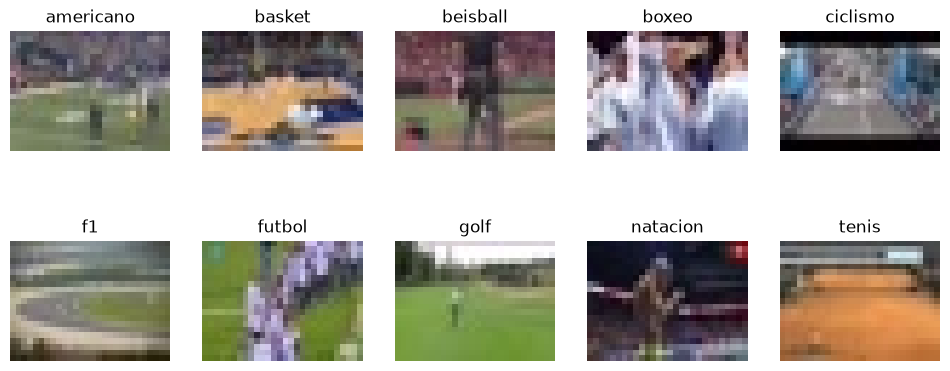

In [3]:
# Una imagen de cada deporte
fig, ejes = plt.subplots(2, 5, figsize=(12, 5))
for c, eje in enumerate(ejes.flat[:len(deportes)]):
    eje.imshow(X[np.flatnonzero(y == c)[0]])
    eje.set_title(deportes[c]); eje.axis("off")
plt.show()

## 2. Entrenamiento, validación y prueba
80 % / 20 %; del 80 % se aparta otro 20 % para validar en cada época.

**Ojo:** las imágenes son cuadros seguidos de videos (`basket_0001`, `basket_0002`, ...). Si se revuelven al azar,
la prueba queda llena de cuadros casi idénticos a los de entrenamiento y la exactitud sale inflada.
Con `DIVISION = "video"` la prueba es el último 20 % de cada deporte, que la red nunca vio.

In [4]:
if DIVISION == "video":
    X_ent, X_prueba, y_ent, y_prueba = cnn.dividir_por_orden(X, y, 0.2)
else:
    X_ent, X_prueba, y_ent, y_prueba = cnn.dividir_estratificado(X, y, 0.2, semilla=0)
X_ent, X_val, y_ent, y_val = cnn.dividir_estratificado(X_ent, y_ent, 0.2, semilla=1)
n = len(deportes)
X_ent, X_val, X_prueba = cnn.normalizar(X_ent), cnn.normalizar(X_val), cnn.normalizar(X_prueba)
Y_ent, Y_val, Y_prueba = cnn.one_hot(y_ent, n), cnn.one_hot(y_val, n), cnn.one_hot(y_prueba, n)
print("División:", DIVISION, "|", X_ent.shape, X_val.shape, X_prueba.shape)
print("Etiqueta", y_ent[0], "-> one-hot", Y_ent[0])

División: video | (49361, 21, 28, 3) (12341, 21, 28, 3) (15426, 21, 28, 3)
Etiqueta 3 -> one-hot [0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]


## 3. Modelo
Dos bloques Conv2D → LeakyReLU → MaxPooling → Dropout y un clasificador denso con softmax.

In [5]:
modelo = cnn.construir_modelo(n)
modelo.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 21, 28, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 21, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 11, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 11, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 11, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 6, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2688)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       172,096 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 192,138 (750.54 KB)

 Trainable params: 192,138 (750.54 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Entrenar
Puede tardar varios minutos según la computadora.

In [6]:
historial = modelo.fit(X_ent, Y_ent, validation_data=(X_val, Y_val),
                       epochs=20, batch_size=64, verbose=2)
modelo.save("sport_model.keras")

Epoch 1/20


772/772 - 10s - 13ms/step - accuracy: 0.8210 - loss: 0.5550 - val_accuracy: 0.9460 - val_loss: 0.1652


Epoch 2/20


772/772 - 8s - 10ms/step - accuracy: 0.9458 - loss: 0.1715 - val_accuracy: 0.9780 - val_loss: 0.0717


Epoch 3/20


772/772 - 9s - 11ms/step - accuracy: 0.9651 - loss: 0.1110 - val_accuracy: 0.9873 - val_loss: 0.0394


... (30 outputs left out)

Epoch 19/20


772/772 - 8s - 10ms/step - accuracy: 0.9925 - loss: 0.0241 - val_accuracy: 0.9979 - val_loss: 0.0079


Epoch 20/20


772/772 - 8s - 10ms/step - accuracy: 0.9918 - loss: 0.0243 - val_accuracy: 0.9948 - val_loss: 0.0122


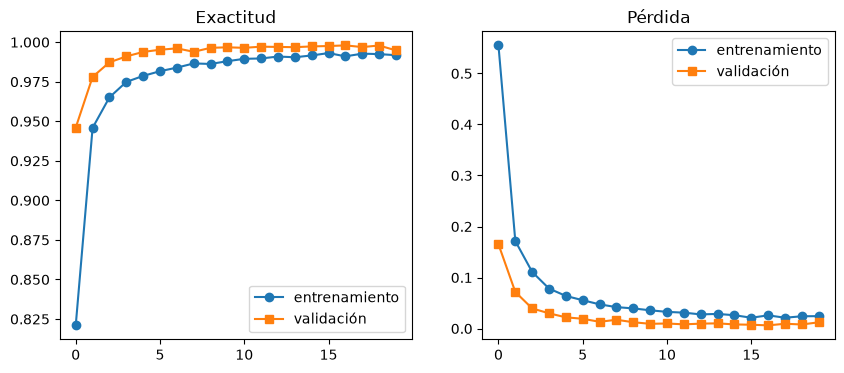

In [7]:
h = historial.history
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1); plt.plot(h["accuracy"], "o-", label="entrenamiento"); plt.plot(h["val_accuracy"], "s-", label="validación"); plt.title("Exactitud"); plt.legend()
plt.subplot(1, 2, 2); plt.plot(h["loss"], "o-", label="entrenamiento"); plt.plot(h["val_loss"], "s-", label="validación"); plt.title("Pérdida"); plt.legend()
plt.show()

## 5. Evaluar con el set de prueba

In [8]:
perdida, exactitud = modelo.evaluate(X_prueba, Y_prueba, verbose=0)
print(f"Pérdida {perdida:.4f}  Exactitud {exactitud:.4f}")
y_pred = modelo.predict(X_prueba, verbose=0).argmax(axis=1)
texto, matriz = cnn.reporte(y_prueba, y_pred, deportes)
print(texto)
print(matriz)

Pérdida 0.7770  Exactitud 0.9070


clase        precision  recall      f1      n
americano         0.67    0.98    0.80   1870
basket            0.87    0.85    0.86   1765
beisball          0.97    0.80    0.88   1550
boxeo             0.98    0.78    0.87   1425
ciclismo          1.00    1.00    1.00   1507
f1                0.89    0.89    0.89   1011
futbol            0.98    1.00    0.99   1523
golf              0.95    0.93    0.94   1954
natacion          1.00    0.74    0.85   1034
tenis             1.00    1.00    1.00   1787
exactitud                               0.9070  15426
[[1841    7   16    2    0    0    2    2    0    0]
 [ 135 1503   15    3    0   98    0   11    0    0]
 [ 251    0 1243    0    0    0   18   38    0    0]
 [ 263   21    9 1115    0   14    0    3    0    0]
 [   0    0    0    0 1507    0    0    0    0    0]
 [  90    0    0    5    0  895    3   18    0    0]
 [   0    0    0    0    0    0 1523    0    0    0]
 [ 120    4    0   18    0    3    0 1809    0    0]
 [  49  199    0

## 6. Aprender de los errores
Primeras 9 imágenes mal clasificadas: título = predicción / real.

1434 errores de 15426


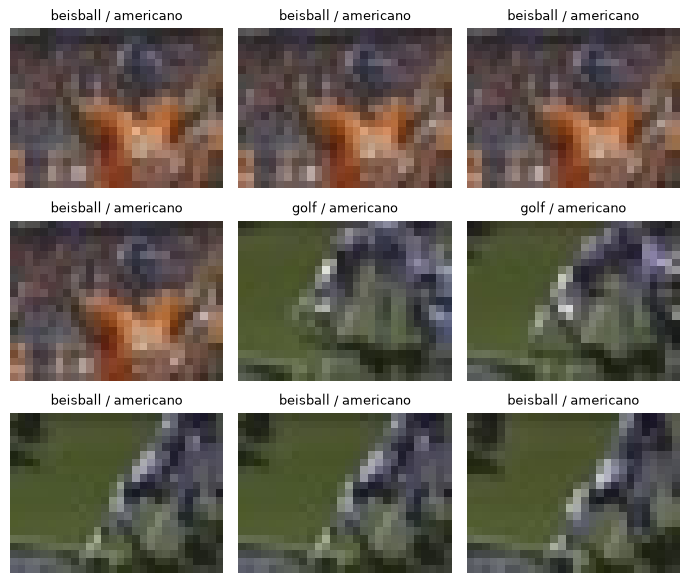

In [9]:
malas = np.flatnonzero(y_pred != y_prueba)
print(len(malas), "errores de", len(y_prueba))
fig, ejes = plt.subplots(3, 3, figsize=(7, 6))
for eje, i in zip(ejes.flat, malas[:9]):
    eje.imshow(X_prueba[i]); eje.axis("off")
    eje.set_title(f"{deportes[y_pred[i]]} / {deportes[y_prueba[i]]}", fontsize=9)
plt.tight_layout(); plt.show()

## 7. Clasificar fotos nuevas
Cualquier tamaño: se reducen a 28×21 igual que el dataset. Aquí se usa la última imagen de algunos deportes;
para una foto propia basta con poner su ruta en la lista.

In [10]:
import json, os
with open("clases.json", "w", encoding="utf-8") as f:
    json.dump(deportes, f, ensure_ascii=False)
fotos = [os.path.join(DATOS, d, sorted(os.listdir(os.path.join(DATOS, d)))[-1]) for d in ["golf", "f1", "natacion"]]
cnn.predecir(fotos, "sport_model.keras", "clases.json")

golf_9870.jpg: golf (100%)
f1_5046.jpg: f1 (100%)
natacion_5550.jpg: basket (90%)


array([[7.9059752e-16, 2.9930276e-33, 7.9144461e-26, 2.9055083e-38,
        0.0000000e+00, 2.3234476e-15, 1.3649421e-37, 1.0000000e+00,
        0.0000000e+00, 4.2796806e-34],
       [1.9184723e-04, 1.3367316e-08, 2.6834863e-13, 2.0145811e-14,
        4.5695876e-14, 9.9980348e-01, 2.9995052e-12, 4.5952852e-06,
        6.4362379e-15, 8.0982741e-13],
       [4.9041584e-03, 9.0106237e-01, 2.2633881e-07, 1.5385725e-06,
        6.1240379e-12, 7.7300083e-10, 1.7977727e-07, 2.0368307e-07,
        9.4031289e-02, 1.7110718e-10]], dtype=float32)